# Part 1B: Code Optimization

**Candidate Name:** Matteo Antony Mistretta

**Date:** 2026-10-17

**Environment:** Python 3.14, requests, numpy, pandas, scikit-learn (exact versions in `requirements.txt`).

*Optimize the naive embedding script and document your approach*

## Overview

**The task.** `naive_embedder.py` sends every anchor text to the embedding API and saves the returned vectors. It works, but slowly. The goal is a faster script, `optimized_embedder.py`, that produces the same embeddings, with timing statistics and an explanation of each optimization.

**The files involved:**

| File | Role |
|---|---|
| `naive_embedder.py` | The provided baseline (not modified) |
| `optimized_embedder.py` | My optimized script; writes `embeddings/anchor.npy` (and `positive.npy` / `negative.npy` with `--include-triplets`) |
| `benchmarks/ablation.py` | Adds one optimization at a time and times each step → `logs/ablation.json` |
| `benchmarks/profile_api.py` | Measures where the time of a request goes, payload sizes, batch-size effects and determinism → `logs/profile.json` |
| `logs/*.log` | The printed output of each timed run |
| `embeddings/naive/`, `embeddings/exact/` | The naive script's output and the `--exact` mode's output, for the correctness check |

**How this notebook works.** Calling the API needs a key and network access, and timings depend on network conditions, so the measurements were made once by running the scripts above from the command line, with no other traffic from my side to the server. This notebook **only reads the saved logs and files**: it can be re-run without an API key, and every number below comes from them.

To reproduce the measurements (≈ 25 minutes, mostly the naive baseline):
```bash
export GPU_MODEL_SERVER_API_KEY=...
python naive_embedder.py --output embeddings/naive/anchor.npy > logs/naive_run_clean.log
python optimized_embedder.py > logs/optimized_run.log
python optimized_embedder.py --include-triplets > logs/optimized_triplets_run.log
python optimized_embedder.py --exact --output-dir embeddings/exact > logs/optimized_exact_run.log
python benchmarks/ablation.py > logs/ablation.log
python benchmarks/profile_api.py > logs/profile.log
```

### Setup

**What:** import the libraries used here and define a helper that extracts a number from a log file.

- `json` reads the `.json` result files; `re` (regular expressions) finds numbers inside the `.log` text files.
- `numpy` / `pandas` hold the embeddings and tables; `matplotlib` draws the chart.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)

def parse_seconds(path, pattern):
    """Return the first number matched by `pattern` in a log file."""
    return float(re.search(pattern, Path(path).read_text()).group(1))

df = pd.read_csv("data/endpoints_data.csv")
profile = json.loads(Path("logs/profile.json").read_text())
print(f"{len(df)} rows, {df['anchor'].nunique()} distinct anchors")

3413 rows, 2761 distinct anchors


## 1. Baseline vs optimized: overall timing

**What:** read the total time of each run from its log and compute the speedup.

**Why:** this is the headline result the task asks for: naive baseline vs optimized, with the speedup calculated.

**How:** each log ends with a line like `COMPLETED in 914.37 seconds` (naive) or `TOTAL: 11.37 s` (optimized); `parse_seconds` extracts it. *Speedup* = naive time / optimized time, adjusted for the number of rows when the run embeds more texts (`--include-triplets` embeds 3 columns).

In [2]:
naive_s = parse_seconds("logs/naive_run_clean.log", r"COMPLETED in ([\d.]+) seconds")
opt_s = parse_seconds("logs/optimized_run.log", r"TOTAL:\s+([\d.]+) s")
exact_s = parse_seconds("logs/optimized_exact_run.log", r"TOTAL:\s+([\d.]+) s")
triplets_s = parse_seconds("logs/optimized_triplets_run.log", r"TOTAL:\s+([\d.]+) s")

timing = pd.DataFrame({
    "configuration": ["naive_embedder.py (baseline)", "optimized_embedder.py --exact",
                      "optimized_embedder.py (default)", "optimized_embedder.py --include-triplets"],
    "rows embedded": [3413, 3413, 3413, 3 * 3413],
    "seconds": [naive_s, exact_s, opt_s, triplets_s],
})
timing["ms per row"] = (timing["seconds"] / timing["rows embedded"] * 1000).round(2)
timing["speedup vs naive"] = (naive_s / timing["seconds"] * timing["rows embedded"] / 3413).round(1)
print(f"Baseline: {naive_s:.0f} s ({naive_s / 60:.1f} min) -> optimized: {opt_s:.1f} s  =>  {naive_s / opt_s:.0f}x speedup")
timing

Baseline: 914 s (15.2 min) -> optimized: 11.4 s  =>  80x speedup


,configuration,rows embedded,seconds,ms per row,speedup vs naive
0,naive_embedder.py (baseline),3413,914.37,267.91,1.0
1,optimized_embedder.py --exact,3413,258.76,75.82,3.5
2,optimized_embedder.py (default),3413,11.37,3.33,80.4
3,optimized_embedder.py --include-triplets,10239,31.00,3.03,88.5


**Observations - timing**
- The naive script takes **914 s (15.2 minutes)** for 3,413 anchors, **268 ms per row**. The optimized script takes **11.4 s**, an **80x speedup** (table above).
- With `--include-triplets` it embeds 10,239 texts in 31 s, 88.5x faster per row than the naive script, because deduplication saves more when three columns share texts.
- `--exact` mode (explained in Section 6) is only 3.5x faster: it keeps the naive one-text-at-a-time pattern on purpose, to reproduce its output bit for bit.
- All timings depend on the network and on the shared test server, so repeated runs vary (Section 5 shows the same configuration taking 12.2-12.3 s in different runs).

## 2. Where does the time go?

**What:** look inside a single request: how long the full round trip takes, versus how long the server says it spent.

**Why:** to optimize, I first need to know whether the time is spent *computing* (the GPU running the model) or *waiting* (network, connection setup). The fixes are completely different.

**How:** the API returns metadata with each response, including `total_time` (server-side processing) and `model_inference_time` (the GPU part). `benchmarks/profile_api.py` sent 10 single-text requests in two ways and recorded the medians:
- with a **new connection** each time, like the naive script (`requests.post`), which repeats the TCP + TLS handshake on every call;
- reusing one **kept-alive connection** (`requests.Session`).

In [3]:
single = pd.Series(profile["single_request"]) * 1000
single.index = ["round trip, kept-alive connection", "round trip, new connection (like naive)",
                "server processing (total_time)", "of which model inference"]
print("Median of 10 single-text requests, in milliseconds:")
print(single.round(1).to_string())
print(f"\nShare of a new-connection request NOT spent on the server: "
      f"{1 - single.iloc[2] / single.iloc[1]:.0%}")

Median of 10 single-text requests, in milliseconds:
round trip, kept-alive connection           63.4
round trip, new connection (like naive)    168.2
server processing (total_time)              10.1
of which model inference                     5.9

Share of a new-connection request NOT spent on the server: 94%


**Observations - where the time goes**
- The server needs only **~10 ms** per request, of which **~6 ms** is the model itself. A new-connection round trip takes **~168 ms**: **94% of each naive request is overhead** (network latency, TCP/TLS handshake, HTTP), not computation.
- Simply reusing the connection cuts the round trip to **~63 ms**.
- The naive script's 268 ms per row (Section 1) is mostly this ~168 ms round trip **plus a 50 ms `time.sleep`** after every call (218 ms together). I cannot attribute the remaining ~50 ms precisely: the baseline and the profiling ran at different times, and network conditions vary.
- **Conclusion:** the work is cheap and the *requests* are expensive. The main lever is to make **far fewer requests**, each doing more work.

## 3. Bottlenecks identified in `naive_embedder.py`

| # | Bottleneck | Evidence / cost |
|---|---|---|
| 1 | **One HTTP request per text**: 3,413 requests, although the API accepts a list | ~94% of each request is overhead (Section 2) |
| 2 | **Strictly sequential**: each request waits for the previous one to finish | The server is multi-GPU (README) and sits idle between requests |
| 3 | **`time.sleep(0.05)` after every request** | 3,413 × 50 ms = **171 s** of pure waiting, 19% of the 914 s runtime |
| 4 | **No connection reuse** (`requests.post` opens a new connection every time) | 168 ms vs 63 ms per request (Section 2) |
| 5 | **Duplicate texts embedded again** | 652 of 3,413 anchors (19%) repeat an earlier one (Part 1A, Section 1) |
| 6 | **Large JSON responses** (found after fixing 1-5) | ~16 KB per embedding, ~43 MB in total (Section 5) |
| 7 | One `print` per text | Minor; noisy output and a little extra time |
| - | No timeout, no status check, no retries | Not a speed issue but a robustness one: a single network error crashes the whole run, and a hung connection blocks it forever |

## 4. Ablation: what each optimization contributes

**What:** time the embedding step while adding **one optimization at a time**, on top of the previous ones.

**Why:** a single before/after number does not say *which* change mattered. An **ablation** (a term from ML: remove or add one component at a time and measure the effect) attributes the speedup to each change.

**How:** `benchmarks/ablation.py` calls the same `embed_texts` function as `optimized_embedder.py` with different settings and saves the times to `logs/ablation.json`. Step 0 is the naive baseline from Section 1. The chart uses a **logarithmic** time axis, where each grid line is 10x the previous one, because the times span from 914 s to 12 s.

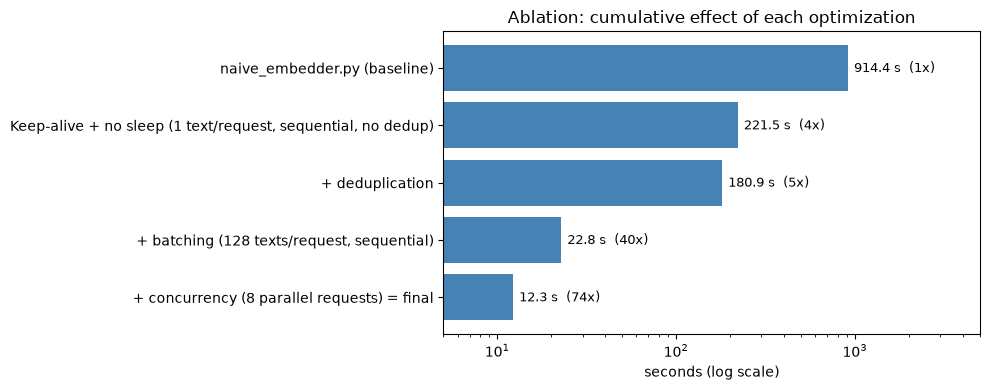

,step,texts,requests,batch_size,workers,gzip,seconds,speedup vs naive
0,naive_embedder.py (baseline),3413,3413,1,1,True,914.37,1.0
1,"Keep-alive + no sleep (1 text/request, sequential, no dedup)",3413,3413,1,1,True,221.49,4.1
2,+ deduplication,2761,2761,1,1,True,180.95,5.1
3,"+ batching (128 texts/request, sequential)",2761,22,128,1,True,22.81,40.1
4,+ concurrency (8 parallel requests) = final,2761,22,128,8,True,12.27,74.5
5,final without gzip (for comparison),2761,22,128,8,False,23.26,39.3


In [4]:
ablation = pd.DataFrame(json.loads(Path("logs/ablation.json").read_text()))
base = pd.DataFrame([dict(step="naive_embedder.py (baseline)", texts=3413, requests=3413,
                          batch_size=1, workers=1, gzip=True, seconds=naive_s)])
ablation = pd.concat([base, ablation], ignore_index=True)
ablation["speedup vs naive"] = (naive_s / ablation["seconds"]).round(1)

cumulative = ablation.iloc[:5]
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(cumulative["step"][::-1], cumulative["seconds"][::-1], color="steelblue")
ax.set_xscale("log")
for bar, s, x in zip(bars, cumulative["seconds"][::-1], cumulative["speedup vs naive"][::-1]):
    ax.text(bar.get_width() * 1.08, bar.get_y() + bar.get_height() / 2, f"{s:.1f} s  ({x:.0f}x)", va="center", fontsize=9)
ax.set(xlabel="seconds (log scale)", title="Ablation: cumulative effect of each optimization", xlim=(5, 5000))
plt.tight_layout(); plt.savefig(FIG_DIR / "1b_ablation.png", dpi=120); plt.show()
ablation[["step", "texts", "requests", "batch_size", "workers", "gzip", "seconds", "speedup vs naive"]]

**Observations - each optimization** (rows of the table above)
1. **Remove the sleep + reuse connections** (`requests.Session`): 914 s → **221 s (4.1x)**. Nothing else changes: still one text per request, one at a time. Per text this is 221 s / 3,413 = 65 ms, matching the 63 ms kept-alive round trip measured in Section 2.
2. **Deduplicate**: → **181 s (5.1x cumulative)**. 2,761 texts instead of 3,413; the results are mapped back to all rows afterwards, so the output still has 3,413 rows in the original order.
3. **Batch 128 texts per request**: → **22.8 s (40x)**, the single biggest win (8x on its own). 2,761 requests become 22, so the per-request overhead is paid 22 times instead of 2,761.
4. **Send 8 batches concurrently**: → **12.3 s (75x)**. While one batch is computed or downloaded, others are in flight; the README says the server is multi-GPU and designed for concurrent requests. Python *threads* are appropriate here because the work is waiting on the network, not computing.
5. **Without gzip compression** the final configuration takes **23.3 s instead of 12.3 s**, so compression is worth ~1.9x (Section 5 explains why).

The order matters for the individual numbers (batching first would look different), but the cumulative result is the same. I used this order because it goes from the simplest change to the most involved.

## 5. After batching: the payload becomes the bottleneck

**What:** measure how the response size and the server's time grow with the batch size, and how the total time depends on batch size and number of concurrent requests (workers).

**Why:** after batching, the remaining time is no longer spent on request overhead. Each embedding is 768 numbers written as **JSON text** (e.g. `0.018079...`), which is much larger than the numbers themselves, so I need to know whether transferring them is now the limit.

**How:** `benchmarks/profile_api.py` sent batches of 1, 32, 128 and 256 texts, each with gzip compression and without (`Accept-Encoding: identity`), recording the bytes actually transferred; then it embedded all 2,761 distinct anchors with several batch size × worker combinations.

In [5]:
by_batch = pd.DataFrame(profile["by_batch_size"]).set_index("batch_size")
by_batch[["server_total_s", "round_trip_gzip_s", "round_trip_plain_s"]] *= 1000
by_batch.columns = ["server ms", "round trip ms (gzip)", "round trip ms (plain)", "KB on wire (gzip)", "KB on wire (plain)"]
print(by_batch.round(1).to_string())
p = profile["payload"]
print(f"\nPer embedding: {p['kb_per_embedding_plain']:.1f} KB of JSON; all 2,761 distinct anchors: "
      f"{p['mb_total_plain']:.1f} MB; gzip makes it {p['gzip_ratio']:.1f}x smaller")
print("\nFull run on 2,761 distinct anchors, by batch size and number of concurrent requests (workers):")
pd.DataFrame(profile["sweep"]).round(1)

            server ms  round trip ms (gzip)  round trip ms (plain)  KB on wire (gzip)  KB on wire (plain)
batch_size                                                                                               
1                10.4                  58.5                   63.7                7.5                16.1
32               25.6                 308.8                  367.5              220.5               507.3
128              79.1                 968.1                 1263.2              877.2              2028.0
256             149.7                1778.5                 2538.2             1752.7              4056.1

Per embedding: 15.8 KB of JSON; all 2,761 distinct anchors: 42.7 MB; gzip makes it 2.3x smaller

Full run on 2,761 distinct anchors, by batch size and number of concurrent requests (workers):


,batch_size,workers,seconds
0,32,8,30.3
1,64,16,13.1
2,128,4,11.2
3,128,8,12.2
4,128,16,13.0
5,256,8,12.2


**Observations - payload and tuning**
- **The GPU is not the limit.** Server time grows from ~10 ms for 1 text to only ~150 ms for 256 texts (first table).
- **The data transfer is.** Each embedding is **~16 KB of JSON**, ~43 MB for all distinct anchors. A 256-text batch is ~4 MB uncompressed, and its round trip is dominated by transferring it. **gzip shrinks it 2.3x**, which is why removing gzip doubled the total time in Section 4. `requests` asks for gzip by default; I set the header explicitly in `make_session` so the optimization is visible and does not get lost.
- **Tuning** (second table): batches of 64-256 with 4-16 workers all finish in **11-13 s**, while batches of 32 were much slower (30 s): small batches mean more requests and more overhead again. More workers do not help past this point because the limit is bandwidth, not the number of requests in flight. I kept **128 texts × 8 workers**: within the API's recommended 32-256 batch size and with a moderate number of parallel connections, which is kinder to a shared server.
- **Possible further gain** outside the client's control: a binary response format would cut the payload ~5x (768 float32 values take 3 KB, versus ~16 KB as JSON text), but that requires changing the server.

## 6. Correctness: are the embeddings identical?

**What:** compare the embeddings produced by the naive script with those of `--exact` mode and of the default (batched) mode.

**Why:** the README requires the optimized script to produce identical embeddings, verified by comparing shapes and spot-checking values.

**How:** for each pair of outputs I check the shape, whether the arrays are **bit-identical** (`np.array_equal`), the share of identical rows, the largest absolute difference between any two values, and the **cosine similarity** between corresponding vectors.

**Cosine similarity** treats each embedding as an arrow in 768-dimensional space and measures the *angle* between two arrows, ignoring their length: **1** = same direction (same meaning), **0** = perpendicular (unrelated), **−1** = opposite. The formula is (a · b) / (|a| × |b|): the dot product (multiply element by element and sum), divided by the two lengths. Embedding models encode meaning in the direction, so this is the measure that matters. I use scikit-learn's `paired_cosine_distances`, which compares row *i* of one array with row *i* of the other and returns the *distance* 1 − similarity.

In [6]:
from sklearn.metrics.pairwise import paired_cosine_distances

naive = np.load("embeddings/naive/anchor.npy")       # output of naive_embedder.py
exact = np.load("embeddings/exact/anchor.npy")       # output of optimized_embedder.py --exact
optimized = np.load("embeddings/anchor.npy")               # output of optimized_embedder.py (default)

def compare(a, b):
    diff = np.abs(a - b).max(axis=1)
    # cosine similarity of row i of a with row i of b: (a . b) / (|a| |b|); the library returns 1 - similarity
    cos = 1 - paired_cosine_distances(a, b)
    return {"same shape": a.shape == b.shape, "bit-identical": np.array_equal(a, b),
            "identical rows": f"{(diff == 0).mean():.1%}", "max |diff|": f"{diff.max():.1e}",
            "mean |diff|": f"{np.abs(a - b).mean():.1e}", "min cosine similarity": f"{cos.min():.5f}"}

print("Shapes:", naive.shape, exact.shape, optimized.shape)
print("Spot check, row 0, first 5 values:")
print("  naive    ", naive[0, :5].round(6))
print("  exact    ", exact[0, :5].round(6))
print("  optimized", optimized[0, :5].round(6))
pd.DataFrame({"--exact vs naive": compare(exact, naive), "default (batched) vs naive": compare(optimized, naive)})

Shapes: (3413, 768) (3413, 768) (3413, 768)
Spot check, row 0, first 5 values:
  naive     [ 0.018079  0.023871 -0.001102  0.017036  0.032832]
  exact     [ 0.018079  0.023871 -0.001102  0.017036  0.032832]
  optimized [ 0.018134  0.02386  -0.001174  0.017043  0.032926]


,--exact vs naive,default (batched) vs naive
same shape,True,True
bit-identical,True,False
identical rows,100.0%,0.0%
max |diff|,0.0e+00,8.3e-03
mean |diff|,0.0e+00,5.0e-05
min cosine similarity,1.00000,0.99959


**What:** find out *why* the batched embeddings differ, using the determinism tests from `benchmarks/profile_api.py`.

**How:** 200 distinct anchors were embedded three ways and compared with the naive output: one text per request, sequentially (like the naive script); in batches of 100; and one text per request but with 64 requests in flight at once.

In [7]:
pd.DataFrame(profile["determinism"]).T

,identical_rows_pct,max_abs_diff
"single text per request, sequential",100.0,0.000000
batches of 100,2.0,0.001610
"single text per request, 64 concurrent",70.5,0.000504


**What:** estimate the numeric precision the server computes with, by comparing the size of the batched-vs-single differences with the resolution of common number formats.

**Why:** *precision* is how many significant digits a number format keeps. **float32** (32-bit floating point) keeps about 7; **float16** and **bfloat16** (16-bit, "half precision") keep only about 3, but GPUs often use them for inference because they are about twice as fast and use half the memory. If the differences are far larger than float32 rounding, the computation itself must use fewer digits.

**How:** I check which format the returned values fit exactly, then compare the median *relative* difference between batched and single-text values with each format's resolution (`eps`: the smallest relative step between two numbers it can represent).

In [8]:
rel_diff = np.abs(naive - optimized) / np.maximum(np.abs(naive), 1e-12)
print(f"Returned values exactly representable as float32: {(naive.astype(np.float32) == naive).mean():.0%}, "
      f"as float16: {(naive.astype(np.float16).astype(np.float64) == naive).mean():.0%}")
print(f"Median relative difference, batched vs single: {np.median(rel_diff):.1e}")
print(f"Resolution (eps): float32 {np.finfo(np.float32).eps:.1e} | float16 {np.finfo(np.float16).eps:.1e} | "
      f"bfloat16 {2 ** -7:.1e}")

Returned values exactly representable as float32: 100%, as float16: 0%
Median relative difference, batched vs single: 1.7e-03
Resolution (eps): float32 1.2e-07 | float16 9.8e-04 | bfloat16 7.8e-03


**Observations - correctness**
- **`--exact` mode is bit-identical to the naive output**: same shape, 100% identical rows, maximum difference 0 (first table).
- **The default batched mode is not bit-identical**, but every vector points in essentially the same direction: minimum cosine similarity 0.99959, mean absolute difference 5e-5 (first table).
- **The cause is on the server** (second table): the same text sent alone always returns exactly the same vector (100% identical), but inside a batch the values change slightly (only 2% of rows identical, differences up to ~1.6e-3). The values are returned as float32 (100% fit float32 exactly), but batched and single results differ by ~0.17% (median relative difference), about 14,000x more than float32 rounding (1.7e-3 / 1.2e-7) and of the same size as half-precision resolution (precision check above). This strongly suggests the model **computes internally in half precision**, where every operation is rounded to ~3 digits; since the GPU orders and groups those operations differently for 1 text and for a batch, the rounding errors add up differently. This is an inference from magnitudes, not documented by the server.
- **Neither version is more precise**: both are rounded approximations of the same computation, rounded along different paths (like computing 1/3 to 3 digits in two different orders and getting 0.333 or 0.334). What `--exact` provides is **reproducibility**, not accuracy.
- Even **single-text requests sent concurrently** were not all identical (70.5% in this test): the server evidently **groups simultaneous requests into one GPU batch** ("dynamic batching", common in inference servers). How many get grouped depends on timing, which is why this share varies between runs. A consequence: any run can be affected by other clients using the server at the same time.
- **Trade-off:** bit-identical output requires one text per request with no concurrency, which rules out batching and parallelism, the two optimizations that give most of the speedup. I therefore provide **both modes**: `--exact` for bit-level reproducibility (3.5x faster than naive) and the **default batched mode** (80x) for normal use. The next cell checks whether the tiny differences matter in practice.

**What:** check whether the differences between naive and batched embeddings change anything a downstream task would see.

**How:** two simple checks on all 3,413 anchors, done once with the naive embeddings and once with the batched ones:
- **nearest neighbours**: for each anchor, its 10 most similar anchors; I measure how many of the 10 are the same in both versions;
- **a k-nearest-neighbours classifier** (predicts a category from the 10 most similar labelled anchors), evaluated with 5-fold cross-validation (trained on 4/5 of the data and tested on the remaining 1/5, five times), comparing predictions and accuracy.

In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

def neighbours(E, k=10):
    return NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(E).kneighbors(E)[1][:, 1:]

nn_naive, nn_opt = neighbours(naive), neighbours(optimized)
overlap = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(nn_naive, nn_opt)])
knn = KNeighborsClassifier(10, metric="cosine")
pred_naive = cross_val_predict(knn, naive, df["case"], cv=5)
pred_opt = cross_val_predict(knn, optimized, df["case"], cv=5)
print(f"Top-10 nearest-neighbour overlap (naive vs optimized): {overlap:.1%}")
print(f"kNN predictions identical on {(pred_naive == pred_opt).mean():.1%} of rows; "
      f"accuracy naive {(pred_naive == df['case']).mean():.3f} vs optimized {(pred_opt == df['case']).mean():.3f}")

Top-10 nearest-neighbour overlap (naive vs optimized): 96.4%
kNN predictions identical on 99.8% of rows; accuracy naive 0.683 vs optimized 0.682


**Observations - practical impact**
- 96.4% of each anchor's 10 nearest neighbours are the same, kNN predictions agree on 99.8% of rows, and kNN accuracy differs by 0.001 (output above). **The differences have no practical effect**, so all later parts use the default batched embeddings in `embeddings/anchor.npy`.

## 7. Robustness

Not a speed issue, but required for a script used in production. In `optimized_embedder.py`:
- every request has a **timeout** (60 s by default), so a hung connection cannot block the run forever;
- **429 (too many requests), 5xx (server error) and connection errors are retried automatically with exponential backoff** (0.5 s, 1 s, 2 s, ... up to 5 attempts), using `urllib3`'s `Retry`. Retrying is safe because embedding a text is *idempotent*: sending it twice gives the same result;
- HTTP errors raise immediately (`raise_for_status`) instead of failing later with a confusing `KeyError` on the response;
- the number of returned embeddings is **validated** against the number of texts sent.

## Part 1B Summary
`optimized_embedder.py` reduces the time to embed the 3,413 anchors from **914 s to 11.4 s (80x)** (Section 1). Profiling showed that **94% of each naive request was overhead**, not computation (Section 2), so the main gains come from making far fewer requests: **batching** (8x on its own) and **removing the sleep + reusing connections** (4x); deduplication, concurrency and gzip compression add 1.2-2x each (Section 4). After batching, the bottleneck becomes the **size of the JSON responses**, which gzip halves (Section 5). The batched output is not bit-identical to the naive one because the GPU server computes batches slightly differently, which has no practical effect (Section 6); an `--exact` mode reproduces the naive output bit for bit when that matters. The script also adds timeouts, retries with backoff, response validation, and `--include-triplets` for Bonus B.